# **Telecommunication Customer Churn Prediction**



### Project Overview

Customer churn is a classification problem in which the objective is to identify customers who are likely to discontinue a service.

In this project, we use the Telco Customer Churn dataset to understand customer characteristics, identify data-quality issues, explore patterns in customer behaviour, and investigate factors associated with customer churn.

The project will progress through the following major stages:

**Data Understanding** — understanding the dataset, its variables, structure, and business meaning.

**Data Cleaning** — identifying and handling data-quality issues such as missing values, duplicate records, incorrect data types, and potential outliers.

**Exploratory Data Analysis (EDA)** — analysing customer characteristics and identifying patterns and relationships associated with churn.

**Feature Engineering and Preprocessing** — preparing the variables for machine-learning algorithms.

**Model Development** — training and comparing Logistic Regression and Random Forest classification models.

**Model Evaluation** — evaluating the models using appropriate classification metrics.

**Prediction and Interpretation** — using the selected model to predict customer churn and identify customer characteristics associated with higher churn risk.

###What We Aim to Achieve
At the end of this project, we aim to develop a customer churn prediction system that can analyse customer information and predict whether a customer is likely to churn.

### Dataset Source
The dataset used for this project is the Telco Customer Churn dataset, obtained from Kaggle. The dataset originates from IBM's sample data sets and contains information about customers of a fictional telecommunications company. It is designed for analysing and predicting customer churn.
The target variable for this project is **`Churn`**.

### 2. Dataset Description

The dataset contains customer-level information that can be divided into several categories:

### Customer Identification
- `customerID`

### Demographic Information
- `gender`
- `SeniorCitizen`
- `Partner`
- `Dependents`

### Account Information
- `tenure`
- `Contract`
- `PaperlessBilling`
- `PaymentMethod`

### Telephone and Internet Services
- `PhoneService`
- `MultipleLines`
- `InternetService`
- `OnlineSecurity`
- `OnlineBackup`
- `DeviceProtection`
- `TechSupport`
- `StreamingTV`
- `StreamingMovies`

### Billing Information
- `MonthlyCharges`
- `TotalCharges`

### Target Variable
- `Churn`

The target variable indicates whether a customer left the company:

- `Yes` → Customer churned
- `No` → Customer did not churn

### 3. Description of Variables

| Column | Description |
|---|---|
| `customerID` | Unique identifier assigned to each customer |
| `gender` | Gender of the customer |
| `SeniorCitizen` | Indicates whether the customer is a senior citizen |
| `Partner` | Indicates whether the customer has a partner |
| `Dependents` | Indicates whether the customer has dependents |
| `tenure` | Number of months the customer has stayed with the company |
| `PhoneService` | Indicates whether the customer has phone service |
| `MultipleLines` | Indicates whether the customer has multiple telephone lines |
| `InternetService` | Type of internet service used by the customer |
| `OnlineSecurity` | Indicates whether the customer has online security |
| `OnlineBackup` | Indicates whether the customer has online backup |
| `DeviceProtection` | Indicates whether the customer has device protection |
| `TechSupport` | Indicates whether the customer has technical support |
| `StreamingTV` | Indicates whether the customer has streaming TV |
| `StreamingMovies` | Indicates whether the customer has streaming movie services |
| `Contract` | Type of contract the customer has |
| `PaperlessBilling` | Indicates whether the customer uses paperless billing |
| `PaymentMethod` | Payment method used by the customer |
| `MonthlyCharges` | Monthly amount charged to the customer |
| `TotalCharges` | Total amount charged to the customer |
| `Churn` | Indicates whether the customer left the company |

## 4. Importing Required Libraries

The following Python libraries will be used throughout this phase of the project.

- **Pandas** is used for data manipulation and analysis.
- **NumPy** is used for numerical operations.
- **Matplotlib** is used for data visualisation.
- **Seaborn** is used to create statistical and exploratory visualisations.

In [ ]:
# Import pandas for data manipulation and analysis
import pandas as pd

# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib for creating visualisations
import matplotlib.pyplot as plt

# Import Seaborn for statistical data visualisation
import seaborn as sns

# Set the visualisation style for the EDA charts
sns.set_theme(style="whitegrid")

# Display plots directly inside the notebook
%matplotlib inline

# Scikit-learn: preprocessing, models, splitting and evaluation.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve)
from sklearn.impute import SimpleImputer

## 5. Loading the Dataset

The dataset is loaded into a Pandas DataFrame named `df`.

After loading the dataset, we will perform an initial inspection to confirm that the data has been loaded correctly.

Before performing any cleaning, we inspect the structure of the dataset.

The following checks will help us understand:

- The number of observations
- The number of variables
- The column names
- The data types
- The presence of missing values
- The general structure of the dataset

Understanding the dataset before cleaning is important because it allows us to identify potential data-quality issues before making any modifications.

In [ ]:
# Load the dataset into a Pandas DataFrame
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display the first five rows of the dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Display the number of rows and columns in the dataset
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7043
Number of columns: 21


In [ ]:
# Display information about the dataset,
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# Display all column names in the dataset
print("Column names:")
print(df.columns)

Column names:
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


In [ ]:
# Generate descriptive statistics for numerical and categorical variables
print("numerical variables:")
print(df.describe())

print("categorical variables:")
print(df.describe(include="object"))

numerical variables:
       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000
categorical variables:
        customerID gender Partner Dependents PhoneService MultipleLines  \
count         7043   7043    7043       7043         7043          7043   
unique        7043      2       2          2            2             3   
top     3186-AJIEK   Male      No         No          Yes            No   
freq             1   3555    3641       4933         6361          3390   

       InternetService OnlineSecurity OnlineBackup DeviceProtection  \
count             7043           7043         7043         

## Data Cleaning

Data cleaning is the process of identifying and addressing problems that may affect the quality and reliability of the analysis.

In this project, the main data-quality checks include:

1. Duplicate records
3. Missing values
4. Blank values
5. Incorrect data types
6. Potential outliers


In [ ]:
# Count the number of completely duplicated rows
duplicate_rows = df.duplicated().sum()

# Display the number of duplicate rows
print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


In [ ]:
# Count missing values in each column
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


#### 11. Checking for Blank Values

Blank strings are different from standard `NaN` values.

Therefore, we specifically inspect object/string columns for empty or whitespace-only values.

This is particularly important for the `TotalCharges` column that has object has dtype instead of int/float in this dataset.

we convert the dtype to int/float then we Inspect customers affected by the conversion.

In [ ]:
blank_counts = (df == " ").sum()

blank_counts

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
# Remove leading and trailing spaces from TotalCharges
df["TotalCharges"] = df["TotalCharges"].astype(str).str.strip()

In [ ]:
# Convert TotalCharges to a numerical data type
# Invalid/blank values are converted to NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [ ]:
# Check the number of missing TotalCharges values
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [ ]:
# Inspect customers affected by the conversion.
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

display(
    df[df["TotalCharges"].isnull()][
        ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

Missing TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


####Handling Blank Values in `TotalCharges`

The `TotalCharges` column contains **11 blank values**.

These 11 records represent approximately **0.16% of the 7,043 customer records**.

The affected customers have a tenure of zero months, indicating that they are newly joined customers.

Because `TotalCharges` represents the accumulated amount charged to a customer, a customer with zero tenure can reasonably have a total accumulated charge of zero.

We therefore retain these customer records instead of deleting them.

The blank values will first be converted into missing values and then treated as zero for customers with zero tenure.

In [ ]:
# These records have zero tenure in the standard dataset,
# so their accumulated TotalCharges can be represented as zero.
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [ ]:
# Confirm that the missing values have been handled
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
# Define the numerical variables to be checked for potential outliers
outlier_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

In [ ]:
# Create an empty list to store the results
outlier_results = []

In [ ]:
# Calculate IQR statistics for each numerical variable
for column in outlier_columns:

    # Calculate the first quartile
    Q1 = df[column].quantile(0.25)

    # Calculate the third quartile
    Q3 = df[column].quantile(0.75)

    # Calculate the interquartile range
    IQR = Q3 - Q1

    # Calculate the lower and upper boundaries
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    # Identify observations outside the IQR boundaries
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    # Store the results
    outlier_results.append({
        "Variable": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Number of Outliers": len(outliers)
    })

# Convert the results into a DataFrame
outlier_summary = pd.DataFrame(outlier_results)

# Display the outlier summary
outlier_summary

,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Number of Outliers
0,tenure,9.00,55.00,46.00,-60.000,124.000,0
1,MonthlyCharges,35.50,89.85,54.35,-46.025,171.375,0
2,TotalCharges,398.55,3786.60,3388.05,-4683.525,8868.675,0


#### Outlier Analysis Insight

The IQR analysis is used to identify unusually high or low values in the numerical variables.

The identified observations are not automatically removed because extreme values may represent legitimate customers with different service usage or billing characteristics.

Therefore, the decision to retain or remove observations should be based on whether the values represent genuine customer records rather than simply whether they fall outside a statistical boundary.

#### Final Data Quality Check

After completing the main cleaning steps, we perform a final quality check.

The purpose of this check is to confirm that:

- The dataset still contains the expected number of customer records.
- No unintended duplicate rows were introduced.
- Missing values have been handled.
- `TotalCharges` has the correct data type.
- The dataset is ready for exploratory analysis.

#### Treatment of "customerID"

The "customerID" column is an identifier assigned to each customer. In a machine-learning project, an identifier does not provide meaningful predictive information and therefore should not be used as an input feature for model training.

However, we will retain "customerID" in the dataset rather than permanently removing it during the data-cleaning and EDA stages.

One reason for this decision is that "customerID" helps us distinguish individual customer records. If the identifier is removed before checking the records, two or more customers whose other attributes are identical may appear as completely duplicated rows to Python, even though they represent different customer records.

Therefore, removing "customerID" at the beginning could cause us to incorrectly interpret some records as duplicate observations and potentially remove valid customer records.

In [ ]:
# Display the final shape of the dataset
print("Dataset shape:", df.shape)

# Check the total number of missing values
print("Total missing values:", df.isnull().sum().sum())

# Check completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check the TotalCharges data type
print("TotalCharges data type:", df["TotalCharges"].dtype)

Dataset shape: (7043, 21)
Total missing values: 0
Duplicate rows: 0
TotalCharges data type: float64


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the underlying patterns, distributions, relationships, and characteristics of the dataset.

The purpose of the EDA is to investigate how different customer characteristics are associated with churn.

The analysis will examine:

1. Overall churn distribution
2. Numerical variable distributions
3. Churn by numerical variables
4. Churn by categorical variables
5. Customer tenure patterns
6. Correlation between numerical variables
7. Relationships between numerical variables and churn

Each major visualisation will be followed by an interpretation of the observed pattern.

In [ ]:
# Identify numerical variables
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

# Identify categorical variables
categorical_columns = df.select_dtypes(include="object").columns.tolist()

# Display numerical variables
print("Numerical variables:")
print(numerical_columns)

# Display categorical variables
print("\nCategorical variables:")
print(categorical_columns)

Numerical variables:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical variables:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [ ]:
# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

# Calculate the percentage of customers in each churn category
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

# Display the counts
print("Churn counts:")
print(churn_counts)

# Display the percentages
print("\nChurn percentages:")
print(churn_percentages.round(2))

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


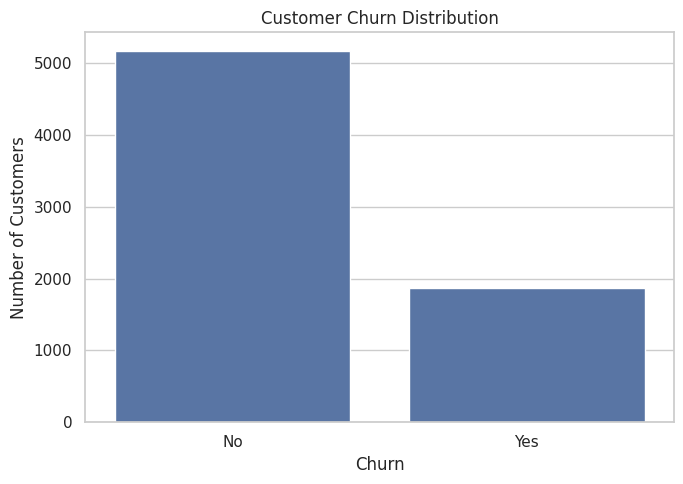

In [ ]:
# Create a bar chart showing the distribution of churn
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

# Add chart title and labels
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

# Display the chart
plt.tight_layout()
plt.show()

#### Insight

The dataset contains approximately:

- **73.46%** customers who did not churn
- **26.54%** customers who churned

This shows that the target variable is not perfectly balanced.

Although the imbalance is not extreme, it should be considered during the machine-learning stage. Model performance should therefore not be evaluated using accuracy alone. Other metrics such as precision, recall, F1-score should also be considered.

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


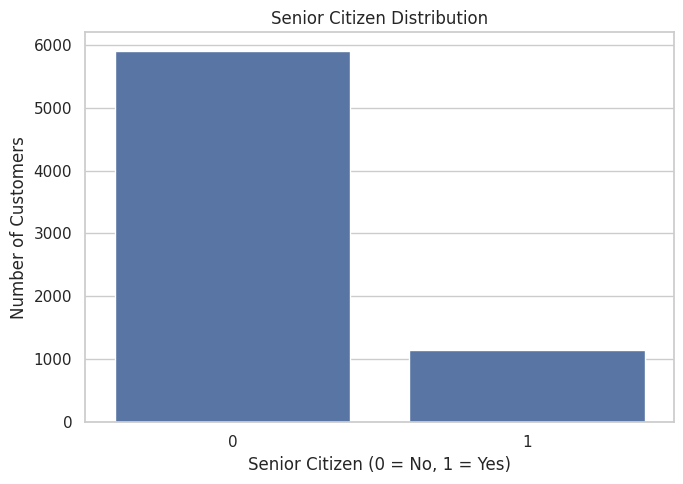

In [ ]:
# Display the number of customers in each SeniorCitizen category
print(df["SeniorCitizen"].value_counts())

# Visualise the SeniorCitizen distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="SeniorCitizen"
)

plt.title("Senior Citizen Distribution")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

#### Insight

`SeniorCitizen` is a binary variable where:

- `0` represents customers who are not senior citizens.
- `1` represents senior citizens.

The distribution shows that the majority of customers are not senior citizens, while senior citizens represent a smaller proportion of the customer population.

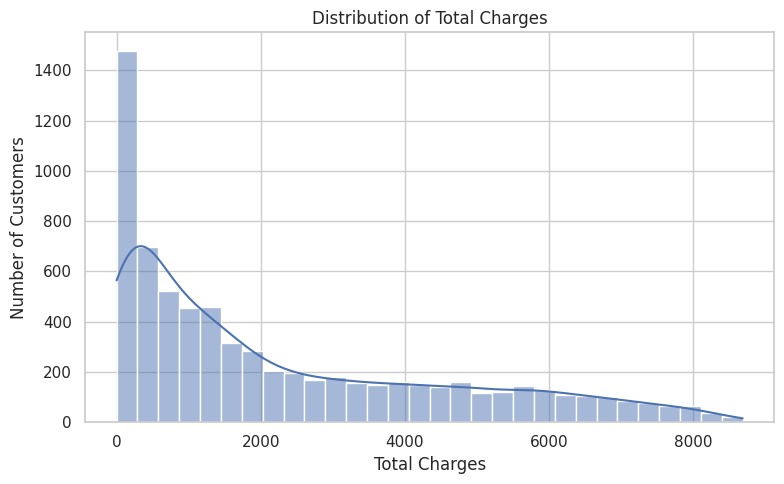

In [ ]:
# Plot the distribution of total charges
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="TotalCharges",
    bins=30,
    kde=True
)

plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

#### Insight

`TotalCharges` represents the total amount charged to a customer over their relationship with the company.

The distribution is influenced by both the customer's monthly charges and their tenure.

Customers with longer tenure generally have more opportunities to accumulate total charges, which explains the relationship between `TotalCharges` and `tenure`.

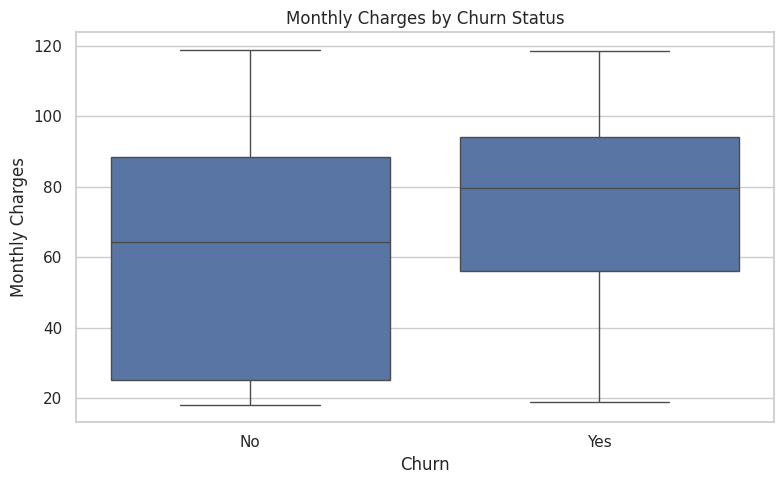

In [ ]:
# Compare monthly charges between churn groups
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

#### Insight

Customers who churned generally show higher monthly charges compared with customers who did not churn.

This suggests that monthly charges may be associated with customer churn.

However, the distributions overlap, meaning that monthly charges alone cannot determine whether an individual customer will churn.

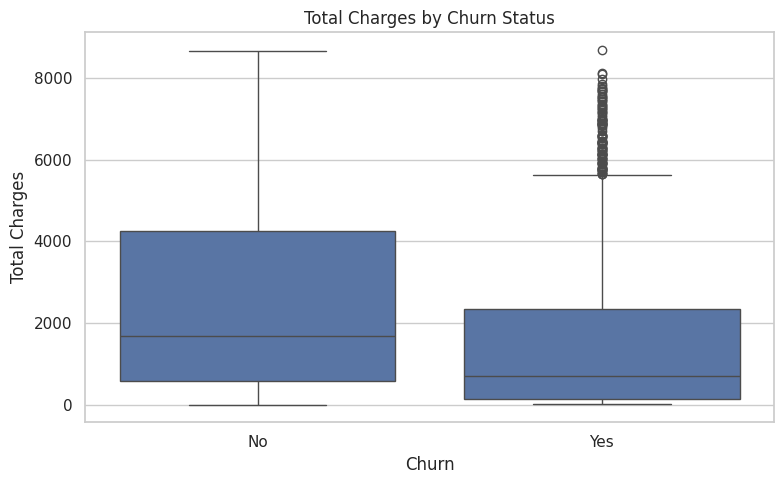

In [ ]:
# Compare total charges between churn groups
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.tight_layout()
plt.show()

#### Insight

The `TotalCharges` distribution differs between churned and non-churned customers.

However, `TotalCharges` must be interpreted together with `tenure` because total charges accumulate over time.

Therefore, a customer with a long tenure can naturally have a higher `TotalCharges` value even if their monthly charges are not particularly high.

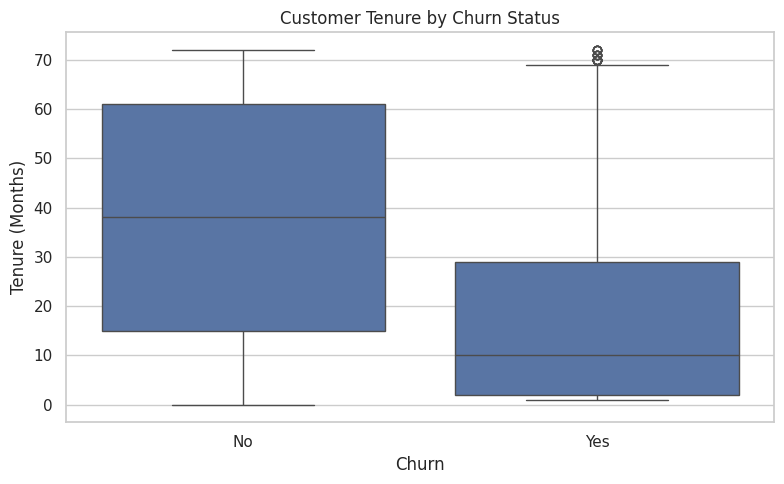

In [ ]:
# Compare customer tenure between churn groups
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

#### Insight

The boxplot shows that customers who churned generally have lower tenure than customers who remained with the company.

This indicates an observed negative relationship between customer tenure and churn.

In practical terms, customers with shorter relationships with the company appear more represented among the churned customers.

However, this is an association observed in the dataset and does not by itself prove that low tenure causes churn.

In [ ]:
# Calculate churn rate by gender
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

# Display the churn rates
gender_churn.round(2)

Churn,No,Yes
gender,,
Female,73.08,26.92
Male,73.84,26.16


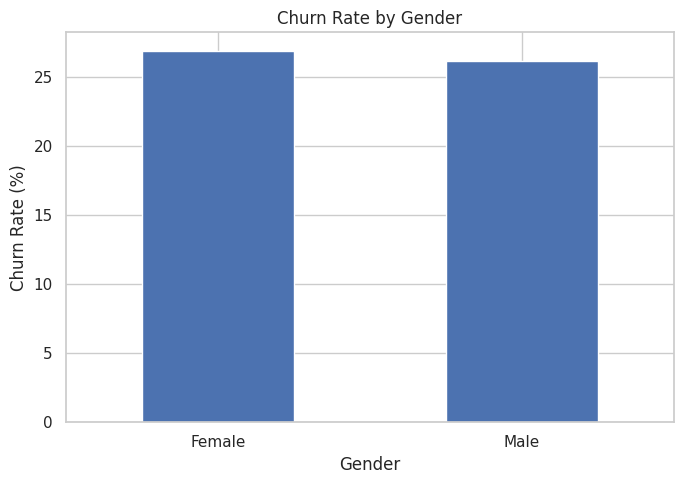

In [ ]:
# Plot churn rate by gender
plt.figure(figsize=(7, 5))

gender_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Insight

The observed churn rates for male and female customers are very similar.

The analysis shows approximately:

- Female: **26.92%**
- Male: **26.16%**

This suggests that gender does not show a large difference in observed churn rate in this dataset.

In [ ]:
# Calculate churn rate by senior citizen status
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

# Display the churn rates
senior_churn.round(2)

Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


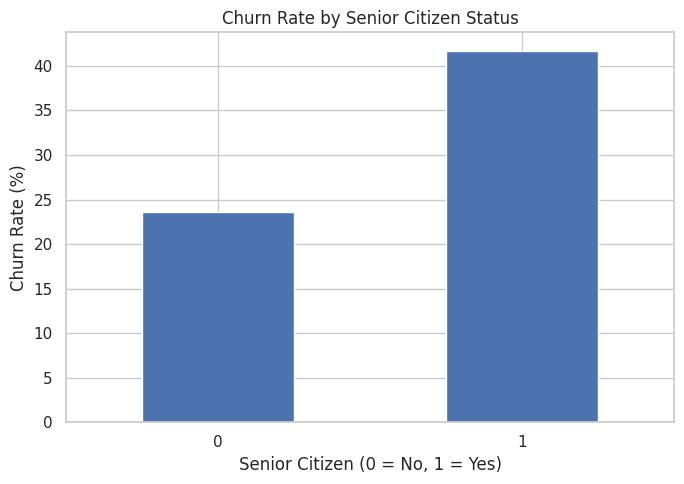

In [ ]:
# Plot churn rate by senior citizen status
plt.figure(figsize=(7, 5))

senior_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Insight

The observed churn rate is higher among senior citizens than non-senior citizens.

The source analysis reports approximately:

- Senior citizens: **41.68%**
- Non-senior citizens: **23.61%**

This indicates an association between senior-citizen status and churn in this dataset.

In [ ]:
# Calculate churn rate by partner status
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

partner_churn.round(2)

Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


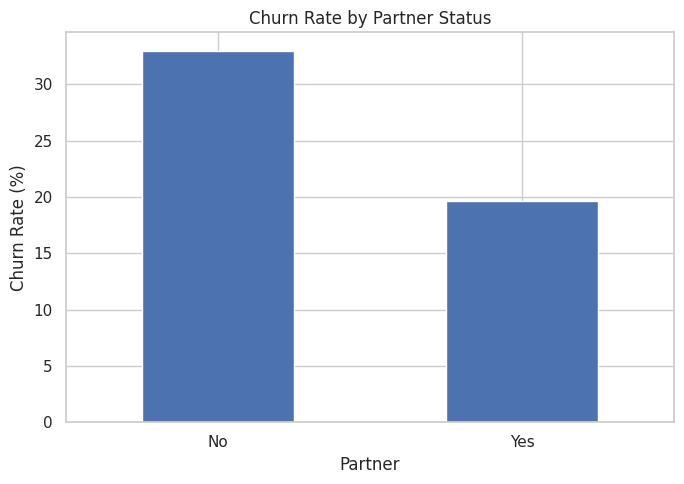

In [ ]:
# Plot churn rate by partner status
plt.figure(figsize=(7, 5))

partner_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Insight

Customers without a partner have a higher observed churn rate than customers with a partner.

The source analysis reports approximately:

- No partner: **32.96%**
- Has partner: **19.66%**

This indicates that partner status is associated with different observed churn rates in the dataset.

In [ ]:
# Calculate churn rate by internet service type
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn.round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


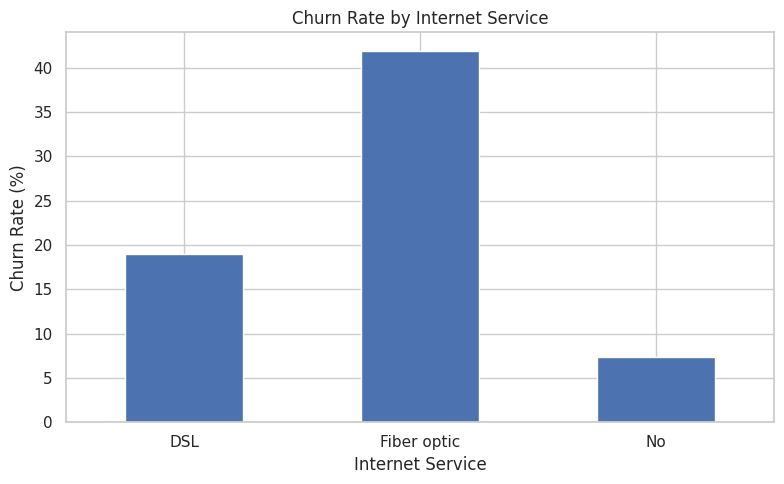

In [ ]:
# Plot churn rate by internet service
plt.figure(figsize=(8, 5))

internet_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Insight

There is a noticeable difference in observed churn rates across internet-service categories.

The source analysis reports approximately:

- Fiber optic: **41.89%**
- DSL: **18.96%**
- No internet service: **7.40%**

Fiber-optic customers therefore have a substantially higher observed churn rate in this dataset.

This is an association and should not be interpreted as evidence that fiber-optic service itself causes churn. Other factors, such as contract type, monthly charges, and additional services, may also contribute to the observed pattern.

In [ ]:
# Select numerical variables for correlation analysis
correlation_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Calculate the correlation matrix
correlation_matrix = df[correlation_columns].corr()

# Display the correlation matrix
correlation_matrix.round(3)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000,0.017,0.220,0.103
tenure,0.017,1.000,0.248,0.826
MonthlyCharges,0.220,0.248,1.000,0.651
TotalCharges,0.103,0.826,0.651,1.000


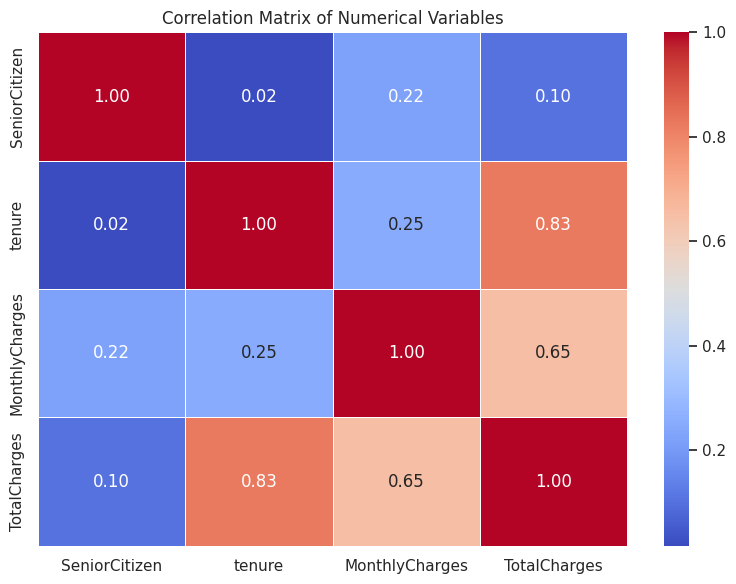

In [ ]:
# Visualise the correlation matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Variables")

plt.tight_layout()
plt.show()

#### Insight

The correlation matrix shows a strong positive relationship between `tenure` and `TotalCharges`.

This relationship is expected because customers who remain with the company for a longer period generally accumulate more total charges.

`MonthlyCharges` also has a positive relationship with `TotalCharges`, because customers paying higher monthly amounts can accumulate larger total charges over time.

These relationships should be considered when interpreting the numerical variables during the modelling stage.

#### Summary of Exploratory Data Analysis

The exploratory analysis identified several important patterns in the customer churn dataset.

### Overall Churn

Approximately **26.54%** of customers churned, while **73.46%** remained.

This indicates that the target variable is moderately imbalanced.

### Customer Tenure

Customers with shorter tenure generally show higher observed churn rates.

The tenure analysis and tenure-group analysis both support this pattern.

### Contract Type

Contract type shows a substantial difference in observed churn.

Month-to-month customers have a considerably higher observed churn rate than customers on one-year and two-year contracts.

### Internet Service

Fiber-optic customers have a higher observed churn rate than DSL customers and customers without internet service.

### Payment Method

Electronic-check customers show a relatively high observed churn rate compared with several other payment-method categories.

### Online Security and Technical Support

Customers without online security or technical support show higher observed churn rates than customers with these services.

### Partner and Dependents

Customers without partners and customers without dependents show higher observed churn rates than their respective comparison groups.

### Numerical Variables

`tenure` shows a negative relationship with churn, while `MonthlyCharges` shows a positive relationship.

### Important Interpretation

The relationships identified during EDA represent patterns and associations in the dataset.

They should not be interpreted as proof that any individual variable directly causes customer churn.

These findings will guide the next stage of the project, where the variables will be prepared for machine-learning models.

## 11. Data Preprocessing

Preprocessing is the stage where the cleaned dataset is transformed into a format that can be effectively used by machine-learning algorithms.

The preprocessing stage for this project consists of:

1. Feature engineering where meaningful new features can improve the representation of customer behaviour.
2. Separating predictor variables from the target variable.
3. Splitting the dataset into training and testing sets.
4. Identifying numerical, binary, and categorical variables.
5. Scaling continuous numerical variables where appropriate.
6. Encoding categorical variables using one-hot encoding.
7. Applying the transformations consistently using Scikit-learn pipelines.

Every preprocessing decision is based on the nature of the variable and the requirements of the machine-learning algorithms used in this project.

#### Feature Engineering

Feature engineering involves creating meaningful variables from existing information in the dataset.

The engineered features used in this project represent:

- Customer spending behaviour
- Number of additional services subscribed to
- Whether the customer has internet service
- Whether the customer uses streaming services
- Contract type
- Payment method
- Internet service type

The target variable `Churn` is not used to create any of these features because doing so would introduce target leakage.

In [ ]:
# Calculate the customer's average spending per month based on total charges and tenure.
# For customers with zero tenure, MonthlyCharges is used because division by zero is undefined.

tenure_for_calculation = df["tenure"].replace(0, np.nan)

df["AverageMonthlySpend"] = (
    df["TotalCharges"] / tenure_for_calculation
)

df["AverageMonthlySpend"] = df["AverageMonthlySpend"].fillna(
    df["MonthlyCharges"]
)

##### Why This Feature Was Created

| Feature | What it represents | Why it was retained |
|---|---|---|
| `AverageMonthlySpend` | Average monthly spending calculated from total charges and tenure | Provides an additional summary of customer spending behaviour. |

During feature engineering, we identified several new columns that represented information already available in the original dataset. For example, `HasInternetService` and `IsFiberOptic` were derived from `InternetService`, while `IsMonthToMonth` was derived from `Contract`.

We removed these overlapping features, along with `HasStreamingService`, `IsElectronicCheck`, `TotalServices`, and `HasAdditionalServices`, to simplify the model's input features.

The original service, contract, and payment columns remain available to the models. `AverageMonthlySpend` was retained because it provides an additional summary of customer spending, although its contribution to model performance will be assessed through evaluation.

In [ ]:
# Separate the target variable from the predictor variables.
y = df["Churn"]

# Remove the target and customer identifier from the model features.
X = df.drop(columns=["Churn", "customerID"])

# Display the shapes of the feature and target datasets.
print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Feature dataset shape: (7043, 20)
Target dataset shape: (7043,)


The target variable in this project is `Churn`, which represents whether a customer left the telecom company.

The `customerID` column is retained in the main dataframe because it is useful for identifying individual customer records and checking customer-level information. However, it will not be used as a predictor because it is simply an identifier and does not represent customer behaviour.

All other relevant variables, including the features created during feature engineering, will initially be considered predictor variables.

The target variable is separated before the train-test split so that the target is never included in the preprocessing transformations.

In [ ]:
# Split the features and target into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the resulting dataset sizes.
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 20)
Testing features: (1409, 20)
Training target: (5634,)
Testing target: (1409,)


#### Train-Test Split

Before applying scaling and encoding, the dataset is divided into training and testing sets.

An 80:20 split is used, where:

- 80% of the data is used to train the machine-learning models.
- 20% is reserved for evaluating the models on unseen data.

An 80:20 ratio provides enough observations for the models to learn customer churn patterns while still keeping a sufficiently large portion of the data for independent evaluation.

Stratification is used because the target variable `Churn` is not evenly distributed. It ensures that the proportion of customers who churned and those who did not churn is approximately maintained in both the training and testing sets.

A `random_state` of 42 is used so that the same split can be reproduced whenever the notebook is run.

The predictor variables contain both numerical and categorical data, and each type requires a different preprocessing approach.

Numerical variables contain quantitative values such as tenure and monthly charges.

Categorical variables contain groups or labels such as gender, contract type, and payment method.

The variables are therefore separated into numerical and categorical groups before preprocessing.

Binary features that have already been represented as 0 and 1 will also be treated as numerical features, but they will not be scaled because they are already on a common 0–1 scale.

In [ ]:
# Identify all numerical columns.
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify all categorical columns.
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Display the identified features.
print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AverageMonthlySpend']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
# Define continuous numerical features that contain meaningful numerical magnitudes.
continuous_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "AverageMonthlySpend"
]

# SeniorCitizen is the only binary numerical feature retained.
binary_features = [
    "SeniorCitizen"
]

# Display the updated numerical feature groups.
print("Continuous numerical features:")
print(continuous_features)

print("\nBinary numerical features:")
print(binary_features)

Continuous numerical features:
['tenure', 'MonthlyCharges', 'TotalCharges', 'AverageMonthlySpend']

Binary numerical features:
['SeniorCitizen']


#### Preprocessing Binary Features

The `SeniorCitizen` feature is retained as a binary numerical variable represented by 0 and 1.

- `0`: The customer is not a senior citizen.
- `1`: The customer is a senior citizen.

This variable does not require scaling because it is already represented on a common 0–1 scale. A most-frequent imputation step is included in the preprocessing pipeline to handle any missing values.

The other engineered binary features were removed because they repeated information already represented by the original categorical variables.

In [ ]:
# Create the preprocessing pipeline for continuous numerical features.
continuous_transformer = Pipeline(
    steps=[
        # Replace any missing numerical values with the median.
        ("imputer", SimpleImputer(strategy="median")),

        # Standardise the continuous numerical variables.
        ("scaler", StandardScaler())
    ]
)

print("Continuous numerical preprocessing pipeline created successfully.")

Continuous numerical preprocessing pipeline created successfully.


#### Encoding Categorical Variables

Machine-learning models require numerical input, but several variables in this dataset are categorical.

Examples include:

- `gender`
- `Partner`
- `Dependents`
- `InternetService`
- `Contract`
- `PaymentMethod`

These variables contain categories rather than numerical measurements.

For this project, **One-Hot Encoding** is used instead of Label Encoding.

Label Encoding would assign numerical values such as 0, 1, and 2 to categories. This could incorrectly imply that the categories have an ordered relationship.

For example, assigning:

- Month-to-month = 0
- One year = 1
- Two year = 2

could make the model interpret "Two year" as numerically greater than "One year". These categories are different types of contracts rather than measurements on a numerical scale.

One-Hot Encoding avoids this problem by creating a separate binary column for each category.

For example:

`Contract` can be transformed into:

- `Contract_Month-to-month`
- `Contract_One year`
- `Contract_Two year`

The value in each column indicates whether the customer belongs to that category.

`handle_unknown="ignore"` is used so that the preprocessing pipeline can safely handle a category appearing in the test data that was not present in the training data.

In [ ]:
# Create the preprocessing pipeline for categorical features.
categorical_transformer = Pipeline(
    steps=[
        # Replace missing categorical values with the most frequent category.
        ("imputer", SimpleImputer(strategy="most_frequent")),

        # Convert categorical variables into binary numerical columns.
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

print("Categorical preprocessing pipeline created successfully.")

Categorical preprocessing pipeline created successfully.


#### Preprocessing Binary Features

The binary features created during feature engineering already contain numerical values of 0 and 1.

Examples include:

- `HasAdditionalServices`
- `HasInternetService`
- `HasStreamingService`
- `IsMonthToMonth`
- `IsElectronicCheck`
- `IsFiberOptic`

These variables do not need scaling because they are already represented on a common 0–1 scale.

A simple imputation step is included in case any missing values are present. The most frequent value is used because these are binary indicator variables and this preserves the existing representation without introducing additional numerical transformations.

In [ ]:
# Create the preprocessing pipeline for binary features.
binary_transformer = Pipeline(
    steps=[
        # Replace any missing binary values with the most frequent value.
        ("imputer", SimpleImputer(strategy="most_frequent"))
    ]
)

print("Binary preprocessing pipeline created successfully.")

Binary preprocessing pipeline created successfully.


#### Combining the Preprocessing Pipelines

The dataset contains three groups of predictor variables that require different preprocessing methods:

| Feature type | Preprocessing | Reason |
|---|---|---|
| Continuous numerical | Median imputation + StandardScaler | Handles missing values and differences in numerical scale |
| Binary | Most-frequent imputation | Already represented on a common 0–1 scale |
| Categorical | Most-frequent imputation + One-Hot Encoding | Converts categories into numerical features without creating artificial ordering |

A `ColumnTransformer` is used to apply the appropriate transformation to each group of columns.

This allows the entire preprocessing process to be managed as one pipeline.

In [ ]:
from sklearn.compose import ColumnTransformer

# Combine the three preprocessing pipelines.
preprocessor = ColumnTransformer(
    transformers=[
        # Apply scaling to continuous numerical features.
        ("continuous", continuous_transformer, continuous_features),

        # Apply imputation to binary features without scaling.
        ("binary", binary_transformer, binary_features),

        # Apply imputation and one-hot encoding to categorical features.
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Complete preprocessing pipeline created successfully.")

Complete preprocessing pipeline created successfully.


#### Fitting and Applying the Preprocessing Pipeline

The preprocessing pipeline is fitted using only the training data.

This is important because the test dataset must remain completely unseen during the learning process.

When the pipeline is fitted on `X_train`, it learns:

- The median values used for numerical imputation.
- The most frequent values used for binary and categorical imputation.
- The mean and standard deviation required by `StandardScaler`.
- The categories required by `OneHotEncoder`.

The learned transformations are then applied to both the training and testing data.

The test data is transformed using the parameters learned from the training data rather than being used to calculate new parameters.

In [ ]:
# Fit the preprocessing pipeline using only the training data.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessing pipeline to the testing data.
X_test_processed = preprocessor.transform(X_test)

# Display the dimensions of the processed datasets.
print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

Processed training data shape: (5634, 46)
Processed testing data shape: (1409, 46)


In [ ]:
# Display the dimensions of the processed datasets.
print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

# Check whether any missing values remain after preprocessing.
print(
    "\nMissing values in training data:",
    np.isnan(X_train_processed).sum()
)

print(
    "Missing values in testing data:",
    np.isnan(X_test_processed).sum()
)

Processed training data shape: (5634, 46)
Processed testing data shape: (1409, 46)

Missing values in training data: 0
Missing values in testing data: 0


## Data Modelling

The modelling stage involves training machine-learning algorithms using the preprocessed training data.

Two classification algorithms are used in this project:

1. Logistic Regression
2. Random Forest Classifier

These models were selected because they provide two different approaches to the customer churn prediction problem.

**Logistic Regression** is a linear classification algorithm that provides a relatively simple and interpretable baseline.

**Random Forest** is an ensemble learning algorithm that combines multiple decision trees and can capture nonlinear relationships and interactions between customer characteristics.

Both models will be trained using the same preprocessed training data so that their performance can be compared fairly during the evaluation stage.

### Logistic Regression

Logistic Regression is used as the first baseline classification model.

It estimates the probability that a customer belongs to a particular class. In this project, the two classes are:

- `No` — the customer does not churn
- `Yes` — the customer churns

Logistic Regression is appropriate for this problem because the target variable is binary.

It also provides a useful baseline against which the more complex Random Forest model can be compared.

The numerical features were standardised during preprocessing because Logistic Regression is sensitive to differences in feature scale.

In [ ]:
# Create the Logistic Regression model.
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the preprocessed training data.
logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


#### Logistic Regression Predictions

After training, the Logistic Regression model is used to make predictions on the testing dataset.

The testing dataset was not used during model training, so these predictions provide an initial indication of how the model performs on unseen customer records.

Two types of predictions will be generated:

- Class predictions, which indicate whether the customer is predicted to churn or not.
- Churn probabilities, which represent the model's estimated probability that a customer will churn.

The probability predictions will be useful later when calculating the ROC-AUC score.

In [ ]:
# Generate class predictions for the test dataset.
y_pred_logistic = logistic_model.predict(X_test_processed)

# Generate predicted probabilities for the positive class (Churn = Yes).
y_prob_logistic = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("Logistic Regression predictions generated successfully.")

Logistic Regression predictions generated successfully.


### Random Forest Classifier

Random Forest is an ensemble machine-learning algorithm that combines multiple decision trees to make a prediction.

Each decision tree learns different patterns from the training data, and the Random Forest combines their predictions to produce a final classification.

Random Forest is suitable for this project because customer churn can depend on nonlinear relationships and interactions between different customer characteristics.

Unlike Logistic Regression, Random Forest does not require numerical features to be scaled. However, the same preprocessed dataset is used here so that both models are evaluated using a consistent feature representation.

The model is configured with 200 decision trees. A `random_state` of 42 is used to make the results reproducible, while `n_jobs=-1` allows the model to use all available CPU cores during training.

In [ ]:
# Create the Random Forest model.
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the Random Forest model using the preprocessed training data.
random_forest_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


#### Random Forest Predictions

The trained Random Forest model is now used to make predictions on the unseen testing data.

As with Logistic Regression, two outputs are generated:

- Class predictions, which indicate whether the customer is predicted to churn.
- Predicted probabilities, which estimate the probability that the customer will churn.

The predicted probabilities will be used later to calculate the ROC-AUC score.

In [ ]:
# Generate class predictions for the test dataset.
y_pred_rf = random_forest_model.predict(X_test_processed)

# Generate predicted probabilities for the positive class (Churn = Yes).
y_prob_rf = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest predictions generated successfully.")

Random Forest predictions generated successfully.


## Model Evaluation

After training the Logistic Regression and Random Forest models, their performance is evaluated using the unseen testing dataset.

Several evaluation metrics are used because accuracy alone may not provide a complete picture of performance, especially when the target classes are imbalanced.

The following metrics are used:

- **Accuracy:** The proportion of all predictions that are correct.
- **Precision:** Of the customers predicted to churn, the proportion who actually churned.
- **Recall:** Of the customers who actually churned, the proportion correctly identified by the model.
- **F1-score:** The harmonic mean of precision and recall.
- **ROC-AUC:** Measures how well the model distinguishes between customers who churn and those who do not across different classification thresholds.

Using multiple metrics provides a more complete evaluation of the models.

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



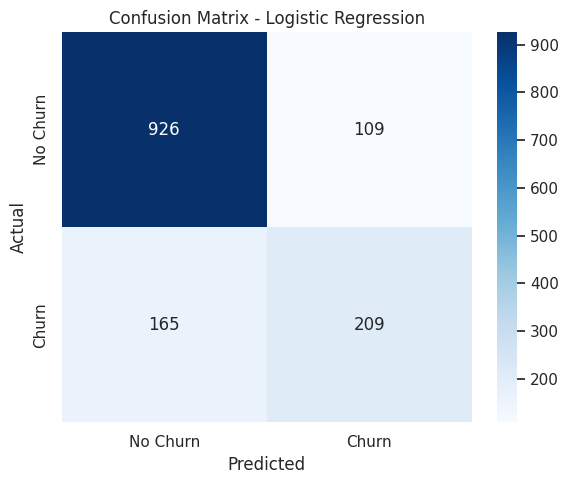

Random Forest
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.62      0.50      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.77      0.79      0.78      1409



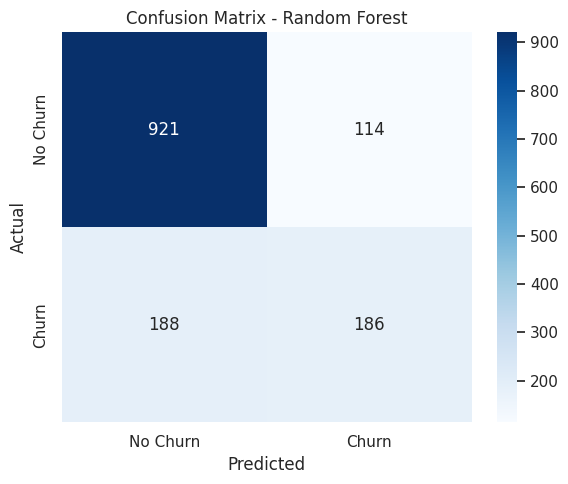

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8420
1,Random Forest,0.7857,0.6200,0.4973,0.5519,0.8236


In [ ]:
def evaluate_model(model, X_test, y_test, model_name):
    # Generate predicted classes.
    y_pred = model.predict(X_test)

    # Generate probabilities for the churn class.
    y_prob = model.predict_proba(X_test)[:, 1]

    # Convert churn labels from "No"/"Yes" to 0/1 for metric calculation.
    y_test_encoded = y_test.map({"No": 0, "Yes": 1})
    y_pred_encoded = pd.Series(y_pred).map({"No": 0, "Yes": 1})

    # Calculate evaluation metrics.
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test_encoded,
            y_pred_encoded
        ),
        "Precision": precision_score(
            y_test_encoded,
            y_pred_encoded,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_encoded,
            y_pred_encoded,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_encoded,
            y_pred_encoded,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test_encoded,
            y_prob
        )
    }

    # Print the classification report.
    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test_encoded,
            y_pred_encoded,
            target_names=["No Churn", "Churn"],
            zero_division=0
        )
    )

    # Plot the confusion matrix.
    cm = confusion_matrix(
        y_test_encoded,
        y_pred_encoded
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return metrics


# Evaluate Logistic Regression and Random Forest.
results = [
    evaluate_model(
        logistic_model,
        X_test_processed,
        y_test,
        "Logistic Regression"
    ),
    evaluate_model(
        random_forest_model,
        X_test_processed,
        y_test,
        "Random Forest"
    )
]

# Convert results to a comparison table.
results_df = pd.DataFrame(results)

display(results_df.round(4))

#### Evaluation Conclusion

##### **1. Logistic Regression Performance**

Logistic Regression achieved an accuracy of approximately **80.55%**, a precision of **65.72%**, a recall of **55.88%**, and an F1-score of **60.40%**.

The accuracy indicates that the model correctly classified approximately 81 out of every 100 customers in the test dataset. Its precision shows that when it predicted a customer would churn, it was correct approximately 66% of the time. Its recall indicates that it successfully identified approximately 56% of the customers who actually churned.

The confusion matrix shows that Logistic Regression correctly identified **209 customers who churned**, while 165 actual churners were incorrectly predicted not to churn. It also correctly identified 926 customers who did not churn, while incorrectly classifying 109 non-churners as potential churners.

These results indicate that Logistic Regression performed reasonably well at distinguishing between customers who would remain with the company and those who would leave.

##### **2. Random Forest Performance**

Random Forest achieved an accuracy of approximately **78.35%**, a precision of **62.00%**, a recall of **49.73%**, and an F1-score of approximately **55.19%**.

Its confusion matrix shows that Random Forest correctly identified **188 customers who churned**, while 186 actual churners were incorrectly predicted not to churn. It also correctly identified 921 customers who did not churn and incorrectly classified 114 non-churners as potential churners.

Although Random Forest achieved reasonable overall accuracy, its recall indicates that it identified only about half of the customers who actually churned. This means that a considerable number of potential churners were missed.

##### **3. Comparison of the Models**

Comparing the two models shows that Logistic Regression achieved better results across the main evaluation metrics.

| Evaluation Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 80.55% | 78.35% |
| Precision | 65.72% | 62.00% |
| Recall | 55.88% | 49.73% |
| F1-Score | 60.40% | 55.19% |

Logistic Regression achieved higher accuracy, meaning that it made a greater proportion of correct predictions overall. It also achieved higher precision, indicating that its churn predictions were more often correct.

Its higher recall is particularly important because the primary objective of this project is to identify customers who are likely to leave the telecommunications company. Logistic Regression correctly identified 209 actual churners, compared with 188 for Random Forest. It also produced fewer false negatives, missing 165 actual churners compared with 186 for Random Forest.

The higher F1-score further indicates that Logistic Regression achieved a better balance between precision and recall.

##### **4. Final Model Selection**

Based on the evaluation results, **Logistic Regression was selected as the preferred model for this customer churn prediction project**.

We selected Logistic Regression because it achieved better performance across accuracy, precision, recall, and F1-score. It also identified more customers who actually churned and missed fewer actual churners than Random Forest.

Although Random Forest can capture complex, non-linear relationships between customer characteristics, its additional complexity did not translate into better predictive performance in this experiment. Logistic Regression provided a more effective result on the test dataset while also offering a relatively straightforward approach to interpreting the factors associated with churn.

##### **5. Overall Conclusion**

The evaluation demonstrates that both Logistic Regression and Random Forest can be applied to the telecommunications customer churn prediction problem, but their performance differs.

Logistic Regression achieved the stronger overall results, with approximately 80.55% accuracy and a 60.40% F1-score. It also identified more actual churners and produced fewer false negatives than Random Forest.

Therefore, Logistic Regression is the preferred model based on the current experiment. Its predictions could help a telecommunications company identify customers who may be at risk of leaving and prioritize suitable customer-retention strategies. Nevertheless, further testing and optimization would be necessary before using the model in a real business environment.

## model-saving


In [ ]:

# Import joblib to save the trained model and preprocessing pipeline.
import joblib
from pathlib import Path

# Create a folder to store the model artifacts.
artifact_dir = Path("model_artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

# Store the trained model, fitted preprocessor, and expected input columns
# together so the Streamlit application can load them consistently.
model_bundle = {
    "model": logistic_model,
    "preprocessor": preprocessor,
    "feature_columns": X.columns.tolist(),
    "model_name": "Logistic Regression",
    "target_classes": logistic_model.classes_.tolist(),
    "feature_engineering": "AverageMonthlySpend"
}

# Save the complete bundle to one file.
model_path = artifact_dir / "logistic_regression_bundle.joblib"
joblib.dump(model_bundle, model_path)

# Confirm that the model bundle was saved.
print(f"Model bundle saved to: {model_path.resolve()}")
print("Included: Logistic Regression model")
print("Included: fitted preprocessing pipeline")
print("Included: expected input feature columns")


Model bundle saved to: /content/model_artifacts/logistic_regression_bundle.joblib
Included: Logistic Regression model
Included: fitted preprocessing pipeline
Included: expected input feature columns


In [ ]:

# Load the saved model bundle from disk.
loaded_bundle = joblib.load(model_path)

# Retrieve the model and preprocessing pipeline.
loaded_model = loaded_bundle["model"]
loaded_preprocessor = loaded_bundle["preprocessor"]

# Transform one test record using the saved preprocessor.
# X_test already contains AverageMonthlySpend, as created in the notebook.
sample_customer = X_test.iloc[[0]].copy()
sample_processed = loaded_preprocessor.transform(sample_customer)

# Generate the prediction and identify the churn probability column.
sample_prediction = loaded_model.predict(sample_processed)[0]
churn_index = list(loaded_model.classes_).index("Yes")
sample_churn_probability = loaded_model.predict_proba(
    sample_processed
)[0, churn_index]

# Display the test result.
print("Saved model loaded successfully.")
print("Predicted churn status:", sample_prediction)
print(f"Estimated churn probability: {sample_churn_probability:.2%}")


Saved model loaded successfully.
Predicted churn status: No
Estimated churn probability: 4.63%
